# Reversibility: train a 19.4M GPT on 50M tokens three ways

1. **Plain GPT** (a10's model at 10 layers), batch 64 x 256 tokens.
2. **Reversible GPT**, same batch: the layers are wired so backward can rebuild each layer's input from its output, so nothing per layer is stored.
3. **Reversible GPT at the largest batch that fits.**

Before the main runs, the notebook checks every reversible variant's gradients against ordinary autograd, measures bf16 against fp16 against fp32, and screens four ways of making layers reversible (coupling, midpoint, euler, momentum) on 5M tokens each. The screening's winner goes into runs 2 and 3.

It runs on Kaggle (2x T4, the record in the README), Colab (1 GPU) or a Mac. With two GPUs, two runs train side by side. `guide.md` explains every step for a reader new to all of this.

Run it top to bottom. If a session dies, run it again: finished runs are skipped and unfinished ones resume from their last checkpoint.

## 1. Parameters

`SMOKE = True` shrinks every stage to toy size (screening 300K tokens, main runs 2M) to check the whole notebook end to end in about 15 minutes. `GPUS = "auto"` uses every CUDA GPU, or the Apple GPU / CPU when there is none.

In [1]:
SMOKE = False      # True: every stage at toy size, to check the notebook end to end
GPUS = "auto"      # "auto", a number of GPUs, or a list of CUDA ids such as [0, 1]
OUT_DIR = None     # None: /kaggle/working/a13 on Kaggle, /content/a13 on Colab, runs/ (or runs/smoke) locally
DATA_DIR = None    # None: a Kaggle dataset holding train.bin if attached, else data/fwe50 built by data.py
USE_DRIVE = True  # Colab only: keep OUT_DIR on Google Drive, so a dead session loses nothing
REPO = "https://github.com/nikshrimali/a13-reversibility.git"

## 2. Setup

Finds out where it is running. On Kaggle or Colab the notebook sits alone, so it clones the repo to get `train.py` and the other scripts. Everything heavy runs as a separate process per GPU (see `jobs.py`), so this notebook's own process never holds GPU memory that would skew the memory numbers.

In [8]:
import glob, json, math, os, subprocess, sys

ON_KAGGLE = os.path.exists("/kaggle/working")
try:
    import google.colab  # noqa: F401
    ON_COLAB = True
except ImportError:
    ON_COLAB = False

if not os.path.exists("train.py"):
    if not os.path.exists("a13-reversibility/train.py"):
        subprocess.run(["git", "clone", "--depth", "1", REPO], check=True)
    os.chdir("a13-reversibility")
sys.path.insert(0, os.getcwd())
if ON_KAGGLE or ON_COLAB:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "tokenizers", "pyarrow", "huggingface_hub", "matplotlib"],
                   check=False)

if ON_COLAB and USE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
if OUT_DIR is None:
    if ON_KAGGLE:
        OUT_DIR = "/kaggle/working/a13"
    elif ON_COLAB:
        OUT_DIR = "/content/drive/MyDrive/a13" if USE_DRIVE else "/content/a13"
    else:
        OUT_DIR = "runs/smoke" if SMOKE else "runs"
os.makedirs(OUT_DIR, exist_ok=True)
print("platform:", "Kaggle" if ON_KAGGLE else "Colab" if ON_COLAB else "local", "| code in", os.getcwd(), "| outputs in", OUT_DIR)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
platform: Colab | code in /content/a13-reversibility | outputs in /content/drive/MyDrive/a13


## 3. Hardware

Which GPUs this session has. On Kaggle's 2x T4 the list is `[0, 1]` and two runs train at once, one per GPU. A Mac shows `[None]`: one worker on the Apple GPU.

In [9]:
import torch
from jobs import Job, bench_job, detect_gpus, probe_job, run_queue, run_script

gpus = detect_gpus(GPUS)
print("torch", torch.__version__)
if torch.cuda.is_available():
    for i in range(torch.cuda.device_count()):
        p = torch.cuda.get_device_properties(i)
        print(f"GPU {i}: {p.name}, {p.total_memory / 1e9:.1f} GB, compute capability {p.major}.{p.minor}")
else:
    print("no CUDA GPU; device:", "mps" if torch.backends.mps.is_available() else "cpu")
print("workers:", gpus)
FIRST = gpus[0]

torch 2.14.1+cu130
GPU 0: Tesla T4, 15.6 GB, compute capability 7.5
workers: [0]


## 4. Data

50M training tokens of FineWeb-Edu and 0.5M held-out tokens, cut with a10's 4,096-token tokenizer. On Kaggle, attach the dataset made from `data/fwe50` and the notebook finds it. Anywhere else, `data.py` downloads and builds it (a few minutes). The documents are read in a fixed order, so every machine gets the same bytes: the held-out file is byte for byte a10's, and a10's whole 25M-token training file is the first half of this one.

In [10]:
if DATA_DIR is None:
    hits = sorted(glob.glob("/kaggle/input/**/train.bin", recursive=True))
    DATA_DIR = os.path.dirname(hits[0]) if hits else "data/fwe50"
if not os.path.exists(f"{DATA_DIR}/train.bin"):
    subprocess.run([sys.executable, "data.py", "--out", DATA_DIR, "--train-tokens", "50M", "--eval-tokens", "500K",
                    "--tokenizer", "tokenizer.json"], check=True)
meta = json.load(open(f"{DATA_DIR}/meta.json"))
print(DATA_DIR, json.dumps(meta, indent=1))

data/fwe50 {
 "dataset": "HuggingFaceFW/fineweb-edu sample-10BT",
 "vocab_size": 4096,
 "eot_id": 0,
 "dtype": "uint16",
 "tokens": {
  "eval": 500000,
  "train": 50000000
 },
 "docs": {
  "eval": 405,
  "train": 35345
 },
 "chars_per_token": 3.421
}


## 5. Sizes

Every number that changes between the smoke test and the real run, in one place. The real run trains each main model on all 50M tokens once (3,039 steps of 64 x 256 tokens; the last few hundred tokens that do not fill a step are left out).

In [11]:
if SMOKE:
    S = dict(screen="300K", main="2M", eval_every="250K", screen_eval_every="100K", eval_tokens=65536,
             probe_start=16, probe_cap=128, bench_steps=30)
else:
    S = dict(screen="5M", main="50M", eval_every="2.5M", screen_eval_every="500K", eval_tokens=None,
             probe_start=64, probe_cap=1 << 16, bench_steps=100)
BATCH = 64
COMMON = ["--data", DATA_DIR, "--micro-batch", BATCH]
EVAL = ["--eval-tokens", S["eval_tokens"]] if S["eval_tokens"] else []
R = lambda *p: os.path.join(OUT_DIR, *p)
print(S)

{'screen': '5M', 'main': '50M', 'eval_every': '2.5M', 'screen_eval_every': '500K', 'eval_tokens': None, 'probe_start': 64, 'probe_cap': 65536, 'bench_steps': 100}


## 6. Gradient check

The reversible backward never sees the layers' stored inputs; it rebuilds them. If the rebuild or the gradient bookkeeping were wrong, the weights would get wrong gradients while the loss looked normal. So each variant runs one batch twice, reversibly and with ordinary autograd, and every parameter's gradient is compared.

Three setups. In **fp64** on the CPU the exact variants must agree to about 1e-14. On the GPU in training precision (fp16 autocast on a T4) both gradients carry rounding error, so each is compared with an fp64 answer from the same weights: a reversible variant costs nothing if its error is no bigger than plain autograd's. The GPU check runs twice, with the streams between layers stored as **fp32** and as **fixed-point integers**.

In [12]:
if not os.path.exists(R("gradcheck.json")):
    run_script(["gradcheck.py", "--out", R("gradcheck.json")], FIRST)
else:
    print(open(R("gradcheck.json")).read()[:300], "...")
gradcheck = json.load(open(R("gradcheck.json")))


== cpu fp64 weights and streams, exact arithmetic up to 1e-16 ==
variant     loss (plain)    loss (rev)  rev vs plain worst parameter             recon err  plain vs fp64  rev vs fp64
coupling        8.401978      8.401978      2.94e-08 blocks.2.ln2.weight          5.88e-15
midpoint        8.429824      8.429824      2.97e-08 blocks.1.ln1.bias            7.80e-15
euler           8.427931      8.427931      1.72e+00 blocks.0.attn.proj.weight    2.09e+00
momentum        8.439006      8.439006      3.92e-08 blocks.9.mlp.fc.weight       3.75e-15

== cuda fp32 weights, float16 autocast, fp32 streams ==
variant     loss (plain)    loss (rev)  rev vs plain worst parameter             recon err  plain vs fp64  rev vs fp64
coupling        8.392579      8.392579      4.73e-03 blocks.0.ln1.weight          2.02e-03       4.01e-03     4.98e-03
midpoint        8.382627      8.382627      4.70e-03 blocks.0.ln1.weight          3.90e-03       5.81e-03     5.90e-03
euler           8.400675      8.40067

## 7. bf16, fp16 and fp32 speed

A T4 has tensor cores for fp16 (65 TFLOPS on the datasheet) but no hardware path for bf16, which falls back to something near fp32 speed (8.1 TFLOPS). This measures it: a big matmul, then 20 training steps of the plain GPT, in each dtype.

In [13]:
if not os.path.exists(R("precision_speed.json")):
    run_script(["precision.py", "speed", "--out", R("precision_speed.json"), "--batch", 16 if SMOKE else 64], FIRST)
print(json.dumps(json.load(open(R("precision_speed.json"))), indent=1))


dtype   matmul TFLOPS  train tok/s
fp32             4.28       28,238
fp16            26.97       97,397
bf16             2.53       19,305
wrote /content/drive/MyDrive/a13/precision_speed.json
{
 "device": "Tesla T4",
 "matmul_tflops": {
  "fp32": 4.275715672399157,
  "fp16": 26.96699624253482,
  "bf16": 2.531618682155885
 },
 "step": {
  "fp32": {
   "median_step_s": 0.5802161709999609,
   "tok_per_s": 28237.75140869196
  },
  "fp16": {
   "median_step_s": 0.16821842500007733,
   "tok_per_s": 97397.17869782973
  },
  "bf16": {
   "median_step_s": 0.848679876999995,
   "tok_per_s": 19305.276870609832
  }
 }
}


## 8. Screening: which way of making layers reversible works?

Seven runs on the same 5M tokens, same batch, same seed, same data order, and the main runs' learning rate schedule squeezed into 5M tokens (50 warmup steps, then cosine down to 1e-4):

| run | wiring | streams stored as |
|---|---|---|
| `gpt` | a10's plain GPT, the reference | n/a |
| `coupling` | y1 = x1 + A(x2), y2 = x2 + M(y1) | fixed-point integers |
| `coupling_fp32` | same | fp32 |
| `midpoint` | x[n+1] = x[n-1] + F(x[n]) | fixed-point integers |
| `midpoint_fp32` | same | fp32 |
| `momentum` | v' = 0.9 v + 0.1 F(x), x' = x + v' | fp32 |
| `euler` | x[n+1] = x[n] + F(x[n]), undone by 3 fixed-point repeats | fp32 |

Every reversible run also logs how far the rebuilt layer inputs drift from the true ones.

In [14]:
SCREEN = {
    "gpt": ["--arch", "gpt"],
    "coupling": ["--arch", "coupling", "--stream-dtype", "fixed"],
    "coupling_fp32": ["--arch", "coupling", "--stream-dtype", "fp32"],
    "midpoint": ["--arch", "midpoint", "--stream-dtype", "fixed"],
    "midpoint_fp32": ["--arch", "midpoint", "--stream-dtype", "fp32"],
    "momentum": ["--arch", "momentum", "--stream-dtype", "fp32"],
    "euler": ["--arch", "euler", "--stream-dtype", "fp32"],
}
from train import parse_count
screen_steps = parse_count(S["screen"]) // (BATCH * 256)
screen_jobs = [Job(f"screen/{n}", a + COMMON + EVAL + ["--max-tokens", S["screen"], "--eval-every-tokens", S["screen_eval_every"],
                                                       "--recon-every-tokens", S["screen_eval_every"],
                                                       "--warmup", min(50, max(5, screen_steps // 6)), "--sample-tokens", 0],
                   R("screen", n)) for n, a in SCREEN.items()]
run_queue(screen_jobs, gpus)

[start] screen/gpt on GPU 0
  screen/gpt       step 220/305 loss 5.4151 grad_norm 0.383 lr 3.30e-04 86,927 tok/s mfu 15.6% peak 3.54 GB (192 ms)
[done] screen/gpt finished in 1.4 min
[start] screen/coupling on GPU 0
  screen/coupling  step 60/305 loss 6.4313 grad_norm 0.418 lr 9.97e-04 53,021 tok/s mfu 9.5% peak 1.33 GB (302 ms)
  screen/coupling  step 200/305 loss 5.6382 grad_norm 0.469 lr 4.32e-04 53,357 tok/s mfu 9.5% peak 1.33 GB (308 ms)
[done] screen/coupling finished in 2.3 min
[start] screen/coupling_fp32 on GPU 0
  screen/coupling_fp32 step 20/305 loss 7.0666 grad_norm 0.724 lr 4.00e-04 62,789 tok/s mfu 11.2% peak 1.28 GB (246 ms)
  screen/coupling_fp32 step 200/305 loss 5.6339 grad_norm 0.490 lr 4.32e-04 65,291 tok/s mfu 11.7% peak 1.28 GB (250 ms)
[done] screen/coupling_fp32 finished in 1.8 min
[start] screen/midpoint on GPU 0
  screen/midpoint  step 60/305 loss 6.2161 grad_norm 0.628 lr 9.97e-04 56,316 tok/s mfu 10.1% peak 1.33 GB (292 ms)
  screen/midpoint  step 200/305 lo

[Job(name='screen/gpt', args=['--arch', 'gpt', '--data', 'data/fwe50', '--micro-batch', 64, '--max-tokens', '5M', '--eval-every-tokens', '500K', '--recon-every-tokens', '500K', '--warmup', 50, '--sample-tokens', 0], out='/content/drive/MyDrive/a13/screen/gpt', done_file='done.json', resume=True, script='train.py', returncode=0, seconds=84.02051258087158),
 Job(name='screen/coupling', args=['--arch', 'coupling', '--stream-dtype', 'fixed', '--data', 'data/fwe50', '--micro-batch', 64, '--max-tokens', '5M', '--eval-every-tokens', '500K', '--recon-every-tokens', '500K', '--warmup', 50, '--sample-tokens', 0], out='/content/drive/MyDrive/a13/screen/coupling', done_file='done.json', resume=True, script='train.py', returncode=0, seconds=138.03307580947876),
 Job(name='screen/coupling_fp32', args=['--arch', 'coupling', '--stream-dtype', 'fp32', '--data', 'data/fwe50', '--micro-batch', 64, '--max-tokens', '5M', '--eval-every-tokens', '500K', '--recon-every-tokens', '500K', '--warmup', 50, '--samp

## 9. Pick the winner

The rule, fixed before the runs:

1. **Gradients**: on the GPU check (cell 6), the variant's error against fp64 is at most 1.5x plain autograd's.
2. **Undo**: the worst rebuilt layer input at the end of the screening is within 1e-3 of the truth.
3. Among the variants that pass both, the **lowest held-out loss** wins, averaged over the last three measurements (4M, 4.5M and 5M tokens) so that one bad step at the very end cannot decide it. If two are within 0.02 of each other, the **faster** one wins.

The smoke test showed why the average matters: every model, the plain GPT included, has the odd single step where the loss jumps by 1 to 4 and recovers on the next step. One of them landed on a variant's final measurement.

In [15]:
def last(path, kind):
    rows = [json.loads(l) for l in open(path) if f'"type": "{kind}"' in l] if os.path.exists(path) else []
    return rows[-1] if rows else None

def grad_ok(variant, stream):
    for r in gradcheck:
        if r["variant"] == variant and r["stream"] == stream and "rev_vs_fp64" in r:
            return r["rev_vs_fp64"] <= 1.5 * r["plain_vs_fp64"], r["rev_vs_fp64"] / r["plain_vs_fp64"]
    return False, float("nan")

table = []
for n, a in SCREEN.items():
    done = json.load(open(R("screen", n, "done.json")))
    arch = a[1]
    stream = a[3] if len(a) > 3 else None
    rec = last(R("screen", n, "metrics.jsonl"), "recon")
    g_ok, g_ratio = grad_ok(arch, stream) if arch != "gpt" else (True, 1.0)
    r_ok = arch == "gpt" or (rec is not None and rec["max"] <= 1e-3)
    evs = [json.loads(l)["loss"] for l in open(R("screen", n, "metrics.jsonl")) if '"type": "eval"' in l]
    loss = sum(evs[-3:]) / len(evs[-3:])
    table.append(dict(run=n, arch=arch, stream=stream, loss=loss, final=evs[-1], tok_per_s=done["tok_per_s"],
                      grad_ratio=g_ratio, recon=rec["max"] if rec else None,
                      eligible=arch != "gpt" and g_ok and r_ok and loss == loss))
print(f"{'run':<15} {'last 3 avg':>10} {'final':>8} {'tok/s':>9} {'grad err / plain':>17} {'worst undo':>11}  eligible")
for t in table:
    rec = f"{t['recon']:.1e}" if t["recon"] is not None else "-"
    print(f"{t['run']:<15} {t['loss']:>10.4f} {t['final']:>8.4f} {t['tok_per_s']:>9,.0f} {t['grad_ratio']:>17.2f} {rec:>11}  {t['eligible']}")
ok = sorted([t for t in table if t["eligible"]], key=lambda t: t["loss"])
best = ok[0]
close = [t for t in ok if t["loss"] - best["loss"] <= 0.02]
WIN = max(close, key=lambda t: t["tok_per_s"])
WIN_ARGS = SCREEN[WIN["run"]]
json.dump({"table": table, "winner": WIN}, open(R("screening.json"), "w"), indent=2)
print(f"\nwinner: {WIN['run']} (held-out {WIN['loss']:.4f}, {WIN['tok_per_s']:,.0f} tok/s)")

run             last 3 avg    final     tok/s  grad err / plain  worst undo  eligible
gpt                 5.3451   5.3108    88,919              1.00           -  False
coupling            5.5284   5.4939    53,489              0.97     0.0e+00  True
coupling_fp32       5.5202   5.4858    64,724              1.24     2.9e-02  False
midpoint            5.3441   5.3105    57,494              0.95     0.0e+00  True
midpoint_fp32       5.3471   5.3137    63,466              1.02     6.2e-02  False
momentum            5.0994   5.0729    60,623              0.99     6.4e-03  False
euler               6.9230   6.9184    38,632            379.72     3.6e+03  False

winner: midpoint (held-out 5.3441, 57,494 tok/s)


## 10. How each stream format drifts

Takes each reversible variant's screening checkpoint and undoes its layers from the top down, with the streams between layers stored four ways: fixed-point integers, fp32, fp16 and bf16. Fewer bits per number means a bigger rounding step per layer, and the undo has to subtract its way back through all of them. This is the answer to "can we store the streams in bf16?".

In [16]:
if not os.path.exists(R("precision_drift.json")):
    run_script(["precision.py", "drift", "--runs", R("screen"), "--data", DATA_DIR, "--out", R("precision_drift.json")], FIRST)

coupling  streams fixed (trained): worst layer 0.00e+00, per layer from the top 0e+00, 0e+00, 0e+00, 0e+00, 0e+00, 0e+00, 0e+00, 0e+00, 0e+00, 0e+00
coupling  streams fp32  (trained): worst layer 3.35e-02, per layer from the top 1e-06, 7e-06, 1e-05, 2e-05, 3e-05, 4e-05, 6e-05, 1e-04, 3e-04, 3e-02
coupling  streams fp16  (trained): worst layer 1.09e-01, per layer from the top 1e-04, 2e-04, 2e-04, 2e-04, 3e-04, 3e-04, 4e-04, 6e-04, 1e-03, 1e-01
coupling  streams bf16  (trained): worst layer 5.90e-01, per layer from the top 7e-04, 1e-03, 1e-03, 1e-03, 2e-03, 2e-03, 2e-03, 4e-03, 7e-03, 6e-01
midpoint  streams fixed (trained): worst layer 0.00e+00, per layer from the top 0e+00, 0e+00, 0e+00, 0e+00, 0e+00, 0e+00, 0e+00, 0e+00, 0e+00, 0e+00
midpoint  streams fp32  (trained): worst layer 6.23e-02, per layer from the top 1e-08, 9e-06, 4e-05, 5e-05, 1e-04, 1e-04, 2e-04, 2e-04, 4e-04, 6e-02
midpoint  streams fp16  (trained): worst layer 1.74e-01, per layer from the top 2e-04, 2e-04, 3e-04, 3e-04

## 11. The two main runs: plain GPT and the winner, same batch, 50M tokens each

Same batch (64 x 256), same learning rate schedule (a10's: AdamW, peak 1e-3, 50 warmup steps, cosine to 1e-4), same seed and data order. With two GPUs they train side by side, one per GPU. Held-out loss every 2.5M tokens.

The first measured step of each prints its memory bill: the textbook prediction, what autograd actually kept for backward, and the device's own count.

In [17]:
main_jobs = [Job("main/gpt", ["--arch", "gpt"] + COMMON + EVAL + ["--max-tokens", S["main"], "--eval-every-tokens", S["eval_every"],
                                                                  "--recon-every-tokens", 0], R("main", "gpt")),
             Job("main/rev", WIN_ARGS + COMMON + EVAL + ["--max-tokens", S["main"], "--eval-every-tokens", S["eval_every"],
                                                         "--recon-every-tokens", S["eval_every"]], R("main", "rev"))]
run_queue(main_jobs, gpus)
for n in ("gpt", "rev"):
    log = open(R("main", n, "log.txt")).read()
    a, b = log.find("What one step costs"), log.find("after backward")
    print(f"===== {n} =====\n" + log[a: log.find("\n", b)] + "\n")

[start] main/gpt on GPU 0
  main/gpt         step 260/3039 loss 5.2413 grad_norm 0.448 lr 9.89e-04 84,079 tok/s mfu 15.0% peak 3.54 GB (194 ms)
  main/gpt         step 540/3039 loss 4.6071 grad_norm 0.450 lr 9.42e-04 83,705 tok/s mfu 15.0% peak 3.54 GB (196 ms)
  main/gpt         step 840/3039 loss 4.2347 grad_norm 0.545 lr 8.54e-04 85,180 tok/s mfu 15.2% peak 3.54 GB (192 ms)
  main/gpt         step 1120/3039 loss 3.9863 grad_norm 0.518 lr 7.45e-04 84,229 tok/s mfu 15.1% peak 3.54 GB (194 ms)
  main/gpt         step 1400/3039 loss 3.8936 grad_norm 0.527 lr 6.19e-04 84,156 tok/s mfu 15.1% peak 3.54 GB (191 ms)
  main/gpt         step 1700/3039 loss 3.7545 grad_norm 0.522 lr 4.77e-04 84,623 tok/s mfu 15.1% peak 3.54 GB (191 ms)
  main/gpt         step 1980/3039 loss 3.7107 grad_norm 0.520 lr 3.52e-04 84,342 tok/s mfu 15.1% peak 3.54 GB (193 ms)
  main/gpt         step 2280/3039 loss 3.5842 grad_norm 0.523 lr 2.36e-04 84,710 tok/s mfu 15.2% peak 3.54 GB (193 ms)
  main/gpt         step 2

## 12. The largest batch each model can train at

`probe.py` doubles the batch until a step runs out of memory, then bisects to the nearest 8 sequences. Every try is a fresh process running 3 full training steps (forward, backward, AdamW), so the optimizer state is in place and one failure leaves nothing behind. Both models are probed so the gain can be stated: the plain GPT's largest batch against the reversible one's.

In [18]:
probe_jobs = [probe_job(f"probe/{n}", a + ["--data", DATA_DIR, "--start", S["probe_start"], "--cap", S["probe_cap"]], R("probe", n))
              for n, a in (("gpt", ["--arch", "gpt"]), ("rev", WIN_ARGS))]
run_queue(probe_jobs, gpus)
probes = {n: json.load(open(R("probe", n, "probe.json"))) for n in ("gpt", "rev")}
for n, p in probes.items():
    print(f"{n}: largest batch {p['max_batch']} sequences ({p['max_batch'] * 256:,} tokens per step)"
          + (f", {p['first_oom']} runs out of memory" if p["first_oom"] else ", cap reached"))

[start] probe/gpt on GPU 0
[done] probe/gpt finished in 1.0 min
[start] probe/rev on GPU 0
  probe/rev        starting...
  probe/rev        batch    768: fits, peak 13.19 GB
  probe/rev        batch    880: fits, peak 15.08 GB
[done] probe/rev finished in 2.2 min
gpt: largest batch 296 sequences (75,776 tokens per step), 304 runs out of memory
rev: largest batch 888 sequences (227,328 tokens per step), 896 runs out of memory


## 13. Reversible at its largest batch, 50M tokens

The same 50M tokens in far fewer, far bigger steps. The learning rate grows with the square root of the batch (the usual rule for Adam), capped at 3e-3, and warmup stays at 1.6% of the steps, as in the 64-batch runs. So the loss gap to run 2 mixes two effects: fewer steps, and a different learning rate. If a long run hits out-of-memory that the 3-step probe did not, the batch drops by 8 and the run restarts.

In [19]:
n_seq = (meta["tokens"]["train"]) // 257
def maxrun_args(b):
    tokens = parse_count(S["main"])
    steps = min(n_seq // b, tokens // (b * 256))
    lr = min(3e-3, 1e-3 * math.sqrt(b / 64))
    return WIN_ARGS + ["--data", DATA_DIR, "--micro-batch", b, "--max-tokens", S["main"], "--lr", f"{lr:.6f}",
                       "--warmup", max(1, round(0.016 * steps)), "--eval-every-tokens", S["eval_every"],
                       "--recon-every-tokens", S["eval_every"]] + EVAL, steps, lr

B_MAX = probes["rev"]["max_batch"]
for attempt in range(3):
    args_, steps, lr = maxrun_args(B_MAX)
    print(f"batch {B_MAX}: {steps} steps, lr {lr:.2e}")
    [j] = run_queue([Job("main/rev_max", args_, R("main", "rev_max"))], gpus[:1])
    if j.returncode != 3:
        break
    subprocess.run(["rm", "-rf", R("main", "rev_max")])
    B_MAX -= 8

batch 888: 219 steps, lr 3.00e-03
[start] main/rev_max on GPU 0
  main/rev_max     step 5/219 loss 7.0596 grad_norm 0.478 lr 3.00e-03 57,316 tok/s mfu 10.3% peak 15.21 GB (3951 ms)
  main/rev_max     step 20/219 loss 7.0001 grad_norm 0.375 lr 2.97e-03 58,593 tok/s mfu 10.5% peak 15.21 GB (3900 ms)
  main/rev_max     step 40/219 loss 6.7990 grad_norm 0.198 lr 2.83e-03 59,003 tok/s mfu 10.6% peak 15.21 GB (4033 ms)
  main/rev_max     step 40/219 loss 6.7990 grad_norm 0.198 lr 2.83e-03 59,003 tok/s mfu 10.6% peak 15.21 GB (4033 ms)
  main/rev_max     step 60/219 loss 6.5378 grad_norm 0.198 lr 2.59e-03 58,651 tok/s mfu 10.5% peak 15.21 GB (3848 ms)
  main/rev_max     step 80/219 loss 6.3442 grad_norm 0.167 lr 2.27e-03 58,351 tok/s mfu 10.4% peak 15.21 GB (3988 ms)
  main/rev_max     step 80/219 loss 6.3442 grad_norm 0.167 lr 2.27e-03 58,351 tok/s mfu 10.4% peak 15.21 GB (3988 ms)
  main/rev_max     step 100/219 loss 6.2526 grad_norm 0.130 lr 1.90e-03 58,594 tok/s mfu 10.5% peak 15.21 GB (3

## 14. Speed and memory, each run alone on the machine

With two GPUs the main runs shared the machine's 4 CPU cores, which can slow both. These 100-step runs go one at a time on one GPU, with nothing else running, and they are the source of every tok/s and peak-memory number in the README. They also time two configs that were not trained: the plain GPT at its own largest batch, and the winner with fp32 streams, which shows what fixed-point streams cost in speed.

In [23]:
bench = {
    "gpt_b64": ["--arch", "gpt", "--micro-batch", BATCH],
    "rev_b64": WIN_ARGS + ["--micro-batch", BATCH],
    "rev_bmax": WIN_ARGS + ["--micro-batch", B_MAX],
    "gpt_bmax": ["--arch", "gpt", "--micro-batch", probes["gpt"]["max_batch"]],
}
if "--stream-dtype" in WIN_ARGS and WIN_ARGS[WIN_ARGS.index("--stream-dtype") + 1] == "fixed":
    bench["rev_fp32_b64"] = WIN_ARGS[:WIN_ARGS.index("--stream-dtype")] + ["--stream-dtype", "fp32", "--micro-batch", BATCH]
bench_args = lambda a: a + ["--data", DATA_DIR, "--bench-steps", S["bench_steps"]]
jobs_ = run_queue([bench_job(f"bench/{n}", bench_args(a), R("bench", n)) for n, a in bench.items()], gpus[:1])
# A max batch sits at the edge of memory: 100 steps can go over where the 3-step probe did not.
# As with the long run, retry 8 sequences smaller (bench.json records the batch that ran).
for j in jobs_:
    n, a = j.name.split("/")[1], bench[j.name.split("/")[1]]
    for attempt in range(3):
        if j.returncode != 3 or "--micro-batch" not in a:
            break
        i = a.index("--micro-batch") + 1
        a = a[:i] + [a[i] - 8] + a[i + 1:]
        print(f"{n}: out of memory, retrying at batch {a[i]}")
        subprocess.run(["rm", "-rf", R("bench", n)])
        [j] = run_queue([bench_job(f"bench/{n}", bench_args(a), R("bench", n))], gpus[:1])

[skip] bench/gpt_b64: already finished in /content/drive/MyDrive/a13/bench/gpt_b64
[skip] bench/rev_b64: already finished in /content/drive/MyDrive/a13/bench/rev_b64
[skip] bench/rev_bmax: already finished in /content/drive/MyDrive/a13/bench/rev_bmax
[skip] bench/rev_fp32_b64: already finished in /content/drive/MyDrive/a13/bench/rev_fp32_b64
[start] bench/gpt_bmax on GPU 0
[fail] bench/gpt_bmax OUT OF MEMORY in 0.4 min
gpt_bmax: out of memory, retrying at batch 288
[start] bench/gpt_bmax on GPU 0
  bench/gpt_bmax   step 60/100 loss 6.0494 grad_norm 0.334 lr 9.30e-04 97,009 tok/s mfu 17.4% peak 14.91 GB (776 ms)
[done] bench/gpt_bmax finished in 1.4 min


## 15. Results

The table the README quotes. Final loss is the held-out loss on all 0.5M eval tokens after the last step. Speed and memory come from the solo runs of cell 14. MFU counts 6N FLOPs per token (useful work only); HFU adds the FLOPs the reversible backward spends recomputing blocks.

In [24]:
rows = []
for name, run, b in (("plain GPT, batch 64", "gpt", "gpt_b64"), ("reversible, batch 64", "rev", "rev_b64"),
                     ("reversible, max batch", "rev_max", "rev_bmax")):
    d = json.load(open(R("main", run, "done.json")))
    s = json.load(open(R("bench", b, "bench.json")))
    rows.append(dict(run=name, arch=d["arch"], batch=d["micro_batch"], steps=d["steps"], tokens=d["tokens"],
                     final_loss=d["final_eval_loss"], tok_per_s=s["tok_per_s"], peak_alloc_gb=s["peak_alloc"] / 1e9,
                     peak_reserved_gb=s["peak_reserved"] / 1e9, mfu=s["mfu"], hfu=s["hfu"],
                     train_minutes=d["wall_seconds"] / 60, device=s["device"]))
extra = {n: json.load(open(R("bench", n, "bench.json"))) for n in bench
         if n not in ("gpt_b64", "rev_b64", "rev_bmax") and os.path.exists(R("bench", n, "bench.json"))}
for n in bench:
    if not os.path.exists(R("bench", n, "bench.json")):
        print(f"no bench.json for {n} (it failed); left out of the table")
summary = {"rows": rows, "extra_bench": extra, "winner": WIN, "probes": {n: {k: p[k] for k in ("max_batch", "first_oom")}
                                                                         for n, p in probes.items()}}
json.dump(summary, open(R("summary.json"), "w"), indent=2)
pct = lambda v: f"{100 * v:.1f}%" if v is not None else "n/a"
print("| run | batch | steps | final held-out loss | tok/s | peak allocated | peak reserved | MFU | HFU |")
print("|---|---|---|---|---|---|---|---|---|")
for r in rows:
    print(f"| {r['run']} | {r['batch']} | {r['steps']:,} | {r['final_loss']:.4f} | {r['tok_per_s']:,.0f} | "
          f"{r['peak_alloc_gb']:.2f} GB | {r['peak_reserved_gb']:.2f} GB | {pct(r['mfu'])} | {pct(r['hfu'])} |")
for n, s in extra.items():
    print(f"| ({n}, timing only) | {s['micro_batch']} | | | {s['tok_per_s']:,.0f} | {s['peak_alloc'] / 1e9:.2f} GB | "
          f"{s['peak_reserved'] / 1e9:.2f} GB | {pct(s['mfu'])} | {pct(s['hfu'])} |")

| run | batch | steps | final held-out loss | tok/s | peak allocated | peak reserved | MFU | HFU |
|---|---|---|---|---|---|---|---|---|
| plain GPT, batch 64 | 64 | 3,039 | 3.5421 | 85,047 | 3.54 GB | 3.61 GB | 15.2% | 15.2% |
| reversible, batch 64 | 64 | 3,039 | 3.6328 | 56,523 | 1.33 GB | 1.78 GB | 10.1% | 13.2% |
| reversible, max batch | 888 | 219 | 6.0816 | 57,028 | 15.21 GB | 15.46 GB | 10.2% | 13.3% |
| (gpt_bmax, timing only) | 288 | | | 95,779 | 14.91 GB | 15.15 GB | 17.1% | 17.1% |
| (rev_fp32_b64, timing only) | 64 | | | 62,943 | 1.26 GB | 1.70 GB | 11.3% | 14.7% |


## 16. Plots

Written to `plots/` inside the output folder: screening curves, the main loss curves, memory against batch size, peak memory, speed, and the drift of each stream format.

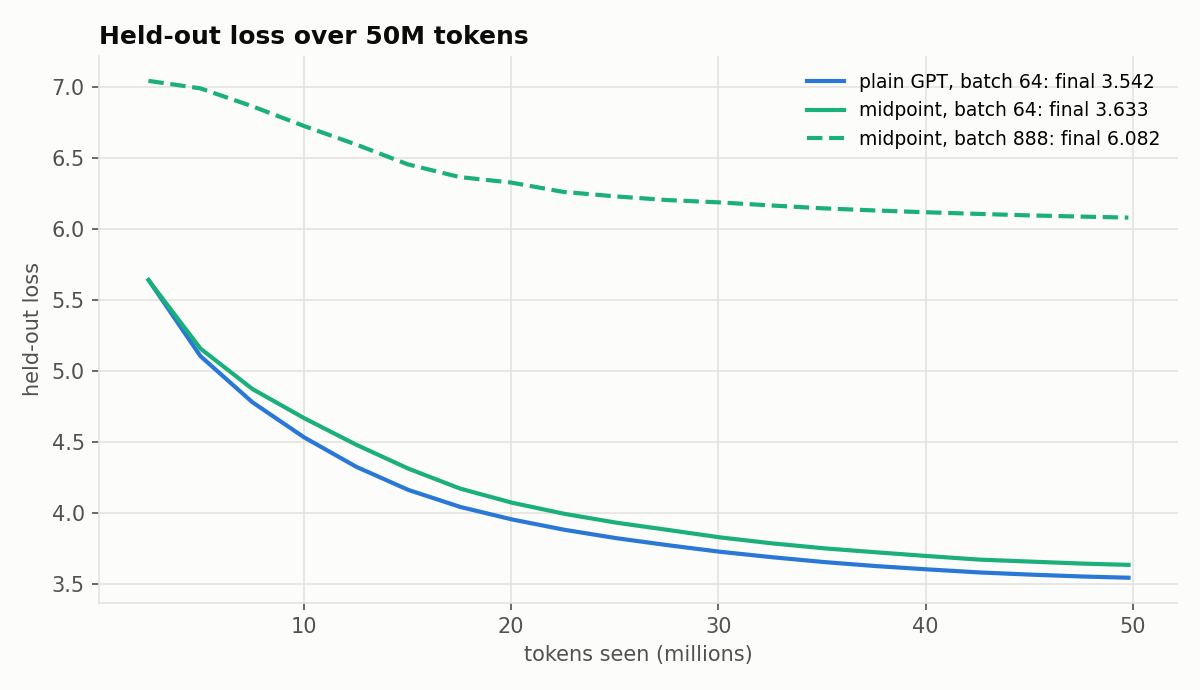

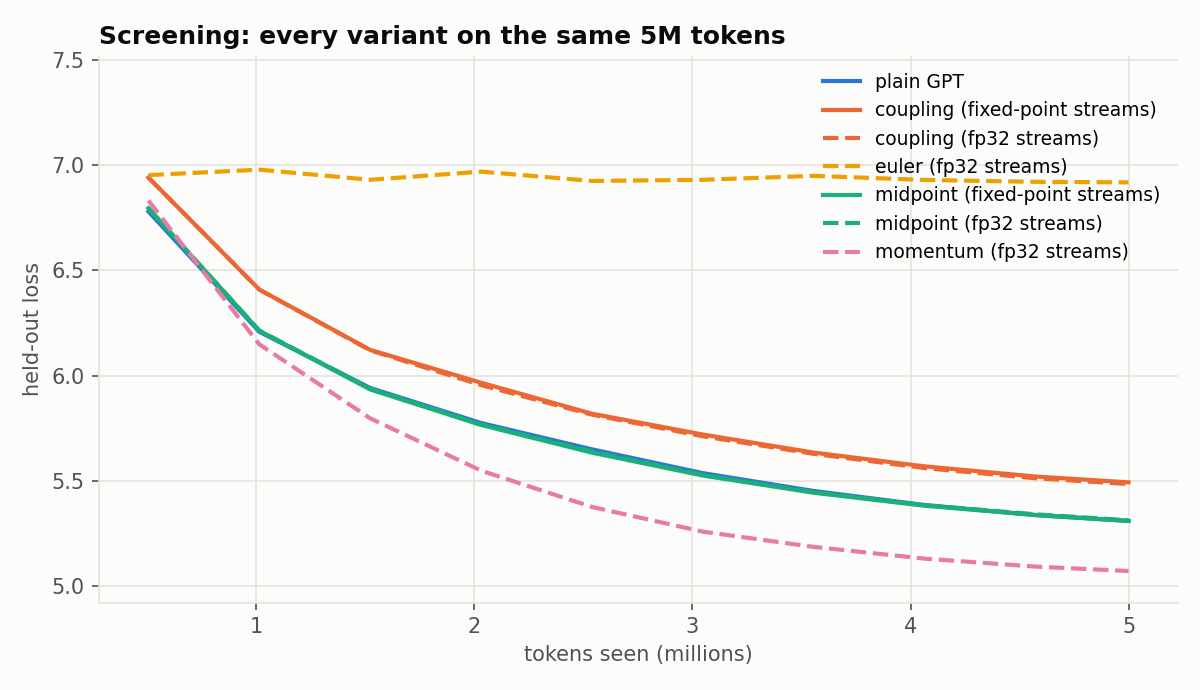

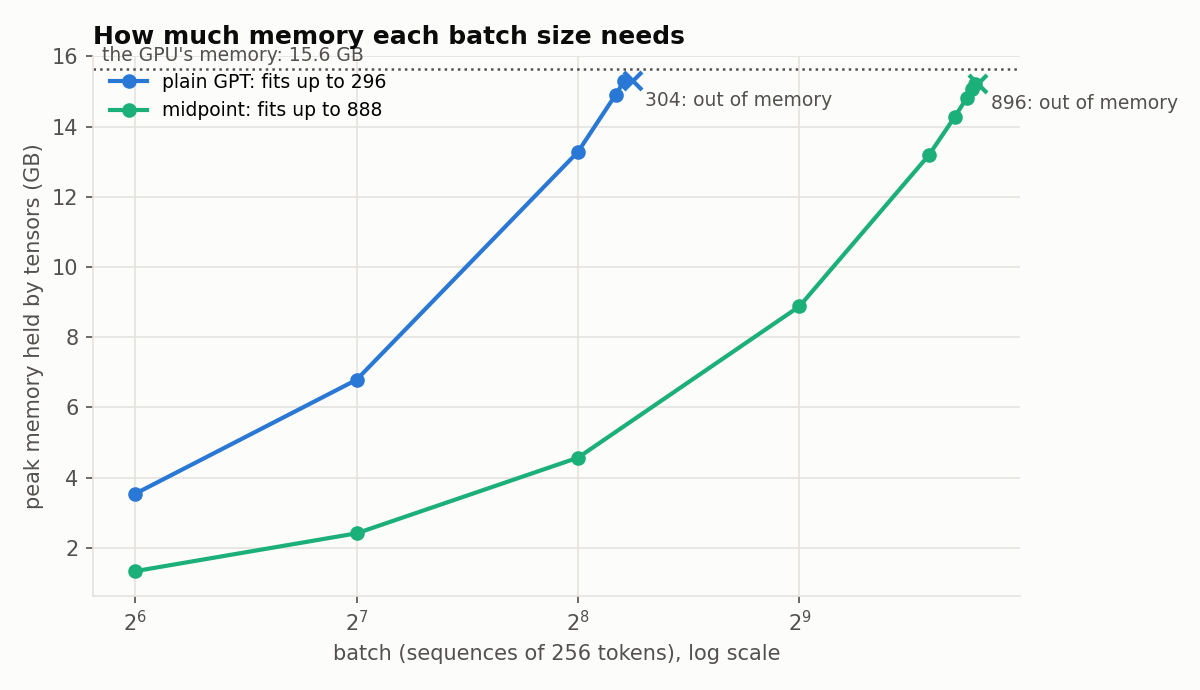

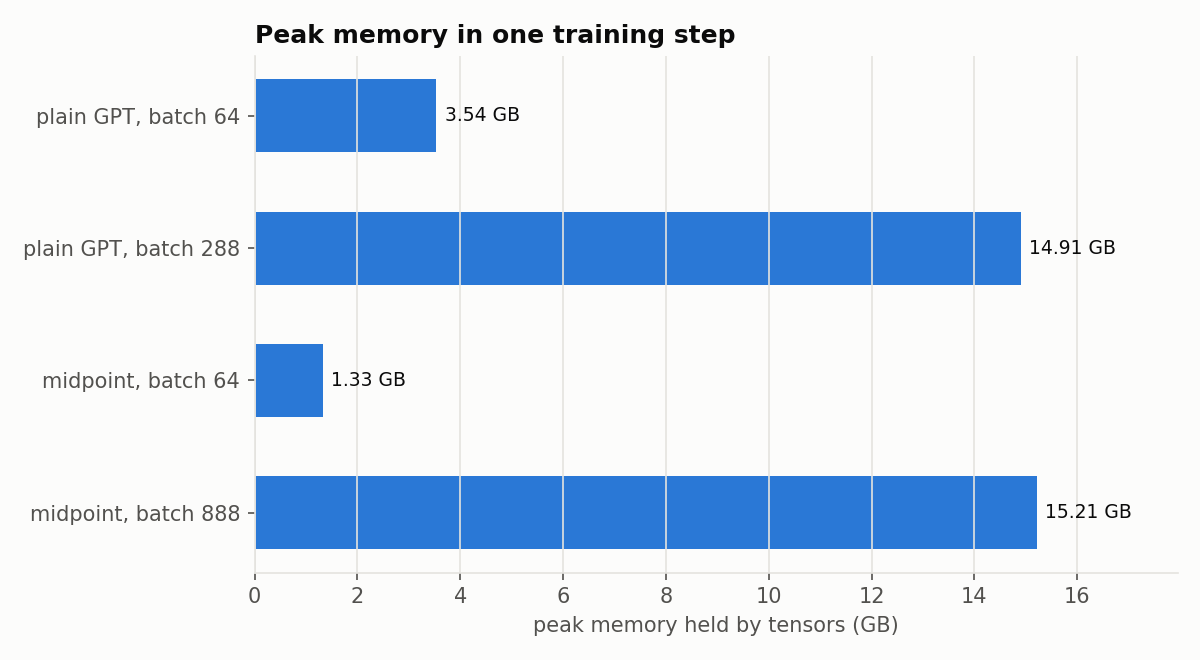

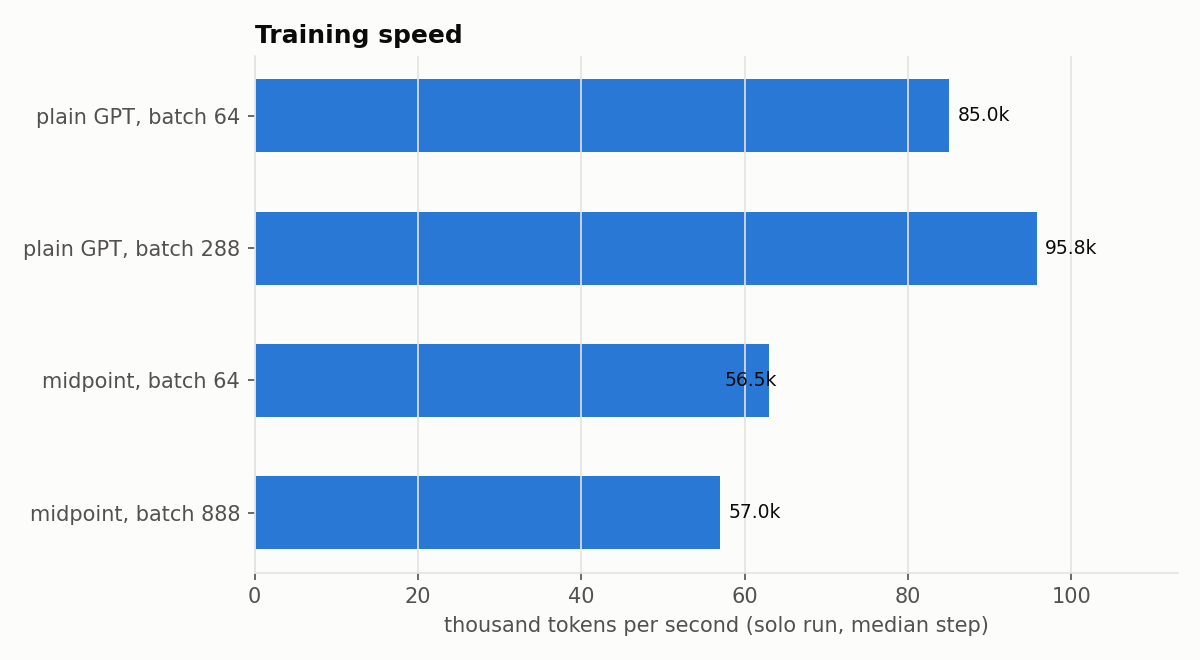

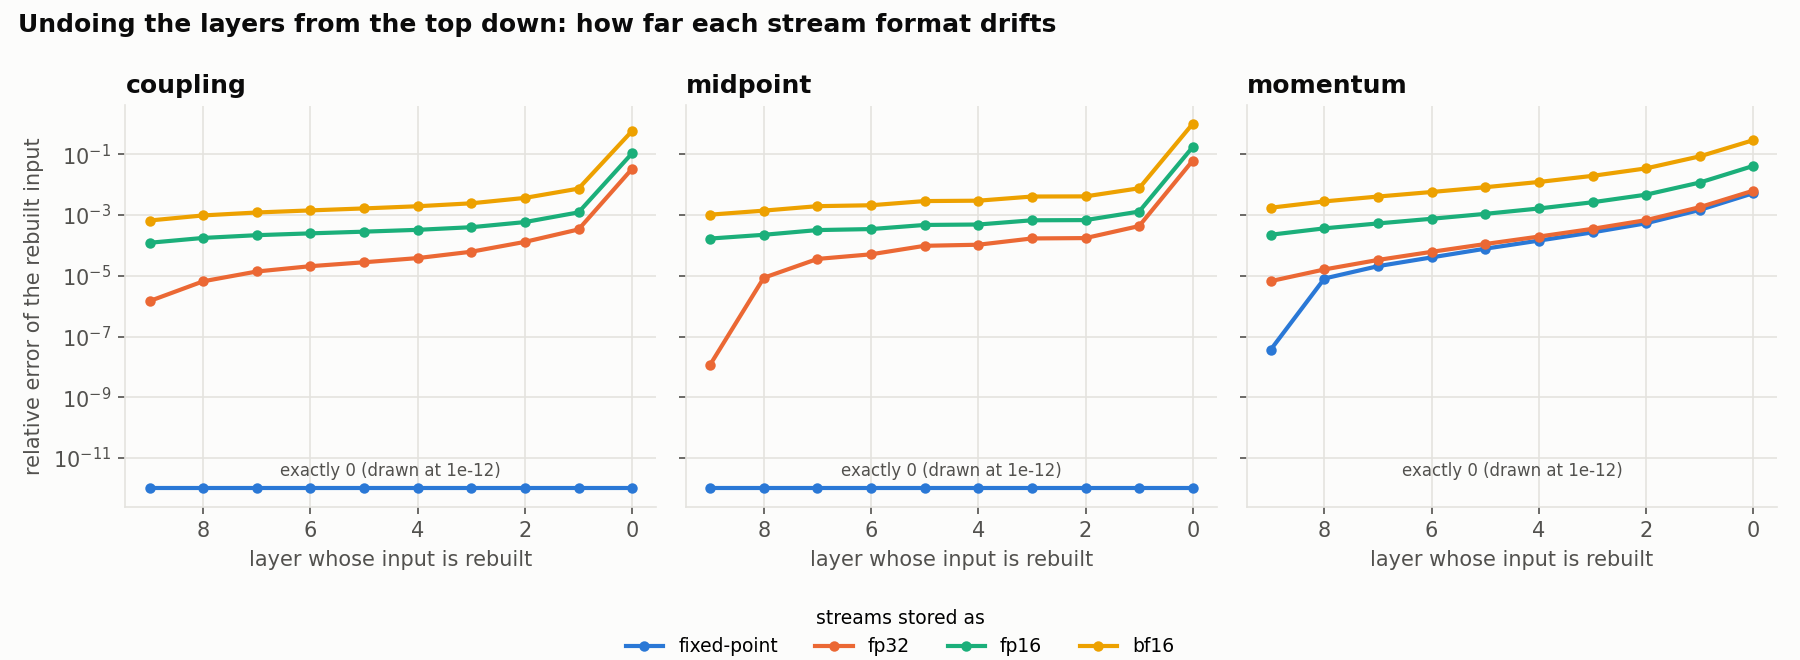

In [25]:
PLOTS = os.path.join(OUT_DIR, "plots")
subprocess.run([sys.executable, "plot.py", "--runs", OUT_DIR, "--out", PLOTS], check=True)
from IPython.display import Image, display
for f in ("main_loss", "screening", "probe", "memory", "speed", "recon"):
    if os.path.exists(f"{PLOTS}/{f}.png"):
        display(Image(f"{PLOTS}/{f}.png"))

## 17. What the models write

Each main run ends by continuing the prompt "The most important thing about learning is" for 200 tokens. At 19.4M parameters and 50M tokens, expect grammatical-looking English that does not stay on topic.

In [26]:
for n in ("gpt", "rev", "rev_max"):
    p = R("main", n, "sample.txt")
    if os.path.exists(p):
        print(f"===== {n} =====\n{open(p).read()}")

===== gpt =====
The most important thing about learning is that in the middle of this day, when it comes to teaching skills. The school of learning is a nice step, but it also takes a good time for children to have the ability to learn through the student, and then they can have the ability to learn.
Most of this is how to learn. Finally, your students will learn to learn about what they want, and why.
In the same year, the teacher will have a full learning experience that is better than others. In this blog, students will learn each other and the students have a more complete learning experience when they are assigned to their learning.
Anyone will have the opportunity to learn, and they will give the child an opportunity to learn and find their own skills through. What is the learning experience for learning?
If learning in order to learn?
In the following days we can learn to learn from our children with learning. We can learn how to learn
What is the

===== rev =====
The most impor